# Sod problem: exact solution and approximate Riemman solvers

Here we compare different approximate Riemann solvers with the exact solution.

First we need to run PLUTO using different approximate solvers. Please edit `pluto.ini` and create 4 different sub-folders in your working directory:

`./Sod_tvdlf/`

`./Sod_hll/`

`./Sod_hllc/`

`./Sod_roe/`

Then, copy the same files from the main `Sod` folder, run the python script, compile with `make` and run with `./pluto`.

In [32]:
# Import libraries
import numpy as np
import pyvista as pv
import matplotlib.pyplot as plt

## 1. Exact solution

The functions of nb18.

In [24]:
# Fix adiabatic index
gamma = 1.4

In [25]:
def sound_speed(rho, p, gamma = 1.4):
    """
    Speed of sound for an ideal gas
    """
    return np.sqrt(gamma*p/rho)


def f_K(p, rhoK, uK, pK, gamma):
    """
    One side of the pressure function, and its derivative.
    """

    cK = sound_speed(rhoK, pK, gamma)

    AK = 2./((gamma + 1.)*rhoK)
    BK = (gamma - 1.)/(gamma + 1.)*pK

    # Shock branch
    if p > pK:
        f = (p - pK)*np.sqrt(AK/(p + BK))
        df = np.sqrt(AK/(BK + p))*(1. - 0.5*(p - pK)/(BK + p))

    # Rarefaction branch
    else:
        f = 2.*cK/(gamma - 1.)*((p/pK)**((gamma - 1.)/(2.*gamma)) - 1.)
        df = 1./(rhoK*cK)*(p/pK)**(-(gamma + 1.)/(2.*gamma))

    return f, df


def star_state(qL, qR, gamma = 1.4, tol = 1.e-12):
    """
    Pressure and velocity in the star region, by the Newton-Raphson method.
    """

    rhoL, uL, pL = qL
    rhoR, uR, pR = qR

    # Initial guess
    p = max(tol, 0.5*(pL + pR))

    # Newton-Raphson on f(p) = fL + fR + (uR - uL)
    for it in range(50):

        fL, dfL = f_K(p, rhoL, uL, pL, gamma)
        fR, dfR = f_K(p, rhoR, uR, pR, gamma)

        p_new = max(tol, p - (fL + fR + uR - uL)/(dfL + dfR))

        if abs(p_new - p) < tol*p_new:
            p = p_new
            break

        p = p_new

    fL = f_K(p, rhoL, uL, pL, gamma)[0]
    fR = f_K(p, rhoR, uR, pR, gamma)[0]

    return p, 0.5*(uL + uR) + 0.5*(fR - fL)


def sample(xi, qL, qR, pstar, ustar, gamma = 1.4):
    """
    Exact state at xi = (x - x0)/t
    """

    rhoL, uL, pL = qL
    rhoR, uR, pR = qR

    cL = sound_speed(rhoL, pL, gamma)
    cR = sound_speed(rhoR, pR, gamma)

    # Left of the contact
    if xi <= ustar:

        # Left wave is a shock
        if pstar > pL:

            S = uL - cL*np.sqrt((gamma + 1.)/(2.*gamma)*pstar/pL + (gamma - 1.)/(2.*gamma))

            if xi < S:
                return rhoL, uL, pL

            ratio = pstar/pL
            rho = rhoL*(ratio + (gamma - 1.)/(gamma + 1.))/((gamma - 1.)/(gamma + 1.)*ratio + 1.)
            return rho, ustar, pstar

        # Left wave is a rarefaction
        c_star = cL*(pstar/pL)**((gamma - 1.)/(2.*gamma))

        if xi < uL - cL:
            return rhoL, uL, pL

        if xi > ustar - c_star:
            return rhoL*(pstar/pL)**(1./gamma), ustar, pstar

        u = 2./(gamma + 1.)*(cL + (gamma - 1.)/2.*uL + xi)
        c = u - xi
        return rhoL*(c/cL)**(2./(gamma - 1.)), u, pL*(c/cL)**(2.*gamma/(gamma - 1.))

    # Right of the contact
    else:

        # Right wave is a shock
        if pstar > pR:

            S = uR + cR*np.sqrt((gamma + 1.)/(2.*gamma)*pstar/pR + (gamma - 1.)/(2.*gamma))

            if xi > S:
                return rhoR, uR, pR

            ratio = pstar/pR
            rho = rhoR*(ratio + (gamma - 1.)/(gamma + 1.))/((gamma - 1.)/(gamma + 1.)*ratio + 1.)
            return rho, ustar, pstar

        # Right wave is a rarefaction
        c_star = cR*(pstar/pR)**((gamma - 1.)/(2.*gamma))

        if xi > uR + cR:
            return rhoR, uR, pR

        if xi < ustar + c_star:
            return rhoR*(pstar/pR)**(1./gamma), ustar, pstar

        u = 2./(gamma + 1.)*(-cR + (gamma - 1.)/2.*uR + xi)
        c = xi - u
        return rhoR*(c/cR)**(2./(gamma - 1.)), u, pR*(c/cR)**(2.*gamma/(gamma - 1.))


def exact(x, t, qL, qR, x0 = 0.5, gamma = 1.4):
    """
    The exact solution on a grid of x at time t.
    """

    ps, us = star_state(qL, qR, gamma)

    return np.array([sample((xk - x0)/t, qL, qR, ps, us, gamma) for xk in x]).T

## 2. I/O:

In [26]:
def read_pluto(number, sim_dir = "./", gamma = 1.4):
    """
    Read a 1D PLUTO VTK file and return x and the primitive variables.
    """

    mesh = pv.read(sim_dir + "data.%04d.vtk" % number)

    # Number of cells and the cell centres along x
    nx = mesh.dimensions[0] - 1

    x_edges = np.linspace(mesh.bounds[0], mesh.bounds[1], nx + 1)
    x = 0.5*(x_edges[:-1] + x_edges[1:])

    # Data arrays, in code units
    rho = pv.get_array(mesh, "rho", preference = 'cell')
    u = pv.get_array(mesh, "vx1", preference = 'cell')
    p = pv.get_array(mesh, "prs", preference = 'cell')

    # Internal energy per unit mass
    e = p/((gamma - 1.)*rho)

    return x, rho, u, p, e

## 3. Runs:

In [27]:
# Snapshot to read
number = 25

runs = {}

# runs["TVDLF"] = read_pluto(number, "./Sod_tvdlf/", gamma)
# runs["HLL"] = read_pluto(number, "./Sod_hll/", gamma)
# runs["HLLC"] = read_pluto(number, "./Sod_hllc/", gamma)
# runs["Roe"] = read_pluto(number, "./Sod_roe/", gamma)

colours = {"TVDLF": "red", "HLL": "tab:blue", "HLLC": "tab:green", "Roe": "tab:magenta"}

## 4. Comparison

In [28]:
# Sod data and final time
qL = (1.0, 0.0, 1.0)
qR = (0.125, 0.0, 0.1)

tend = 0.25

# Exact solution on a fine grid
x_exact = np.linspace(0., 1., 1000)

rho_exact = exact(x_exact, tend, qL, qR, gamma = gamma)[0]

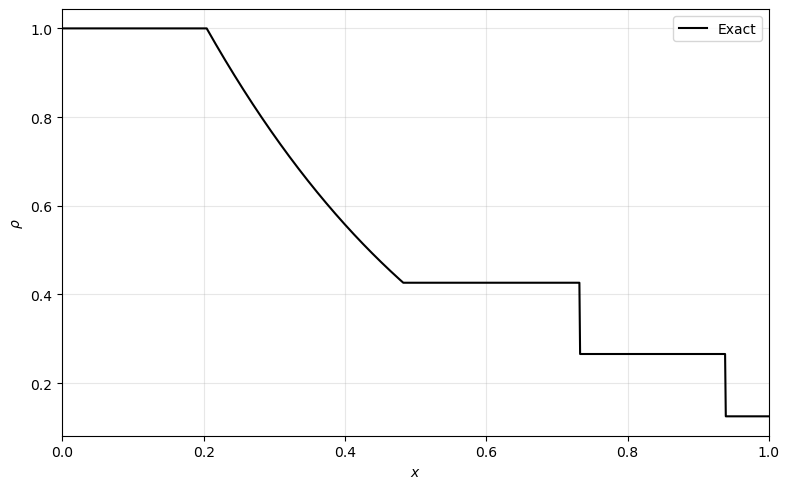

In [29]:
plt.figure(figsize = (8,5))

plt.plot(x_exact, rho_exact, color = "black", lw = 1.5, label = "Exact")

for name in runs:

    x, rho, u, p, e = runs[name]

    plt.plot(x, rho, "o", ms = 3., color = colours[name], label = name)

plt.xlabel(r"$x$")
plt.ylabel(r"$\rho$")
plt.xlim(0., 1.)
plt.grid(alpha = 0.3)
plt.legend()
plt.tight_layout()
plt.show()